In [30]:
from pathlib import Path

OUTPUT_DIR = Path("../visualizations")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy
import psycopg

print("Python EDA environment is ready!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Python EDA environment is ready!
Pandas version: 3.1.0
NumPy version: 2.5.4


In [2]:
import os
from getpass import getpass
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus

DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "ecommerce_customer_intelligence"
DB_USER = input("PostgreSQL username: ")
DB_PASSWORD = getpass("PostgreSQL password: ")

connection_url = (
    f"postgresql+psycopg://{quote_plus(DB_USER)}:"
    f"{quote_plus(DB_PASSWORD)}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

engine = create_engine(connection_url, pool_pre_ping=True)

try:
    with engine.connect() as connection:
        result = connection.execute(text("SELECT version();"))
        print("Database connection successful!")
        print(result.scalar())
except Exception as error:
    print("Connection failed. Check the database settings and credentials.")
    print(type(error).__name__, str(error).splitlines()[0])

Database connection successful!
PostgreSQL 18.6 on x86_64-windows, compiled by msvc-19.44.35229, 64-bit


In [3]:
tables = pd.read_sql_query("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'public'
      AND table_type = 'BASE TABLE'
    ORDER BY table_name;
""", engine)

display(tables)

,table_name
0,olist_customers
1,olist_geolocation
2,olist_order_items
3,olist_order_payments
4,olist_order_reviews
5,olist_orders
6,olist_products
7,olist_sellers
8,product_category_translation


In [4]:
table_names = tables["table_name"].tolist()

for table_name in table_names:
    query = f'SELECT COUNT(*) AS row_count FROM public."{table_name}"'
    count = pd.read_sql_query(query, engine).iloc[0]["row_count"]
    print(f"{table_name}: {count:,} rows")

olist_customers: 99,441 rows
olist_geolocation: 1,000,163 rows
olist_order_items: 112,650 rows
olist_order_payments: 103,886 rows
olist_order_reviews: 99,224 rows
olist_orders: 99,441 rows
olist_products: 32,951 rows
olist_sellers: 3,095 rows
product_category_translation: 71 rows


In [5]:
orders = pd.read_sql_query("""
    SELECT *
    FROM olist_orders
    LIMIT 5;
""", engine)

display(orders)

,order_id,customer_id,order_status,order_purchase_timestamp,order_purchase_date,order_purchase_time,order_approved_at_timestamp,order_approved_at_date,order_approved_at_time,order_delivered_carrier_timestamp,order_delivered_carrier_date,order_delivered_carrier_time,order_delivered_customer_timestamp,order_delivered_customer_date,order_delivered_customer_time,order_estimated_delivery_timestamp,order_estimated_delivery_date,order_estimated_delivery_time
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,02-10-2017 10:56,2017-10-02,10:56:33,02-10-2017 11:07,2017-10-02,11:07:15,04-10-2017 19:55,2017-10-04,19:55:00,10-10-2017 21:25,2017-10-10,21:25:13,18-10-2017 00:00,2017-10-18,00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,24-07-2018 20:41,2018-07-24,20:41:37,26-07-2018 03:24,2018-07-26,03:24:27,26-07-2018 14:31,2018-07-26,14:31:00,07-08-2018 15:27,2018-08-07,15:27:45,13-08-2018 00:00,2018-08-13,00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,08-08-2018 08:38,2018-08-08,08:38:49,08-08-2018 08:55,2018-08-08,08:55:23,08-08-2018 13:50,2018-08-08,13:50:00,17-08-2018 18:06,2018-08-17,18:06:29,04-09-2018 00:00,2018-09-04,00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,18-11-2017 19:28,2017-11-18,19:28:06,18-11-2017 19:45,2017-11-18,19:45:59,22-11-2017 13:39,2017-11-22,13:39:59,02-12-2017 00:28,2017-12-02,00:28:42,15-12-2017 00:00,2017-12-15,00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,13-02-2018 21:18,2018-02-13,21:18:39,13-02-2018 22:20,2018-02-13,22:20:29,14-02-2018 19:46,2018-02-14,19:46:34,16-02-2018 18:17,2018-02-16,18:17:02,26-02-2018 00:00,2018-02-26,00:00:00


In [6]:
schema = pd.read_sql_query("""
    SELECT table_name, column_name, data_type
    FROM information_schema.columns
    WHERE table_schema = 'public'
      AND table_name IN (
          'olist_orders',
          'olist_order_items',
          'olist_customers',
          'olist_products',
          'olist_order_payments',
          'olist_order_reviews'
      )
    ORDER BY table_name, ordinal_position;
""", engine)

display(schema)

,table_name,column_name,data_type
0,olist_customers,customer_id,text
1,olist_customers,customer_unique_id,text
2,olist_customers,customer_zip_code_prefix,text
3,olist_customers,customer_city,text
4,olist_customers,customer_state,text
5,olist_order_items,order_id,text
6,olist_order_items,order_item_id,text
7,olist_order_items,product_id,text
8,olist_order_items,seller_id,text
9,olist_order_items,shipping_limit_date,timestamp without time zone


In [7]:
key_tables = {
    "olist_customers": ["customer_id", "customer_unique_id"],
    "olist_orders": ["order_id", "customer_id", "order_status"],
    "olist_order_items": ["order_id", "product_id", "seller_id", "price"],
    "olist_products": ["product_id", "product_category_name"],
}

for table_name, columns in key_tables.items():
    selected_columns = ", ".join(f'"{col}"' for col in columns)

    df = pd.read_sql_query(
        f"SELECT {selected_columns} FROM public.{table_name}",
        engine
    )

    print(f"\n--- {table_name} ---")
    print("Rows:", len(df))
    print("Missing values:")
    print(df.isna().sum())
    print("Blank strings:")
    print(
        df.select_dtypes(include="object")
          .apply(lambda col: col.str.strip().eq("").sum())
    )


--- olist_customers ---
Rows: 99441
Missing values:
customer_id           0
customer_unique_id    0
dtype: int64
Blank strings:
customer_id           0
customer_unique_id    0
dtype: int64

--- olist_orders ---
Rows: 99441
Missing values:
order_id        0
customer_id     0
order_status    0
dtype: int64
Blank strings:
order_id        0
customer_id     0
order_status    0
dtype: int64


C:\Users\Srushti\AppData\Local\Temp\ipykernel_12840\3587598994.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object")
C:\Users\Srushti\AppData\Local\Temp\ipykernel_12840\3587598994.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#s


--- olist_order_items ---
Rows: 112650
Missing values:
order_id      0
product_id    0
seller_id     0
price         0
dtype: int64
Blank strings:
order_id      0
product_id    0
seller_id     0
dtype: int64

--- olist_products ---
Rows: 32951
Missing values:
product_id                 0
product_category_name    610
dtype: int64
Blank strings:
product_id               0
product_category_name    0
dtype: int64


C:\Users\Srushti\AppData\Local\Temp\ipykernel_12840\3587598994.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object")
C:\Users\Srushti\AppData\Local\Temp\ipykernel_12840\3587598994.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#s

In [8]:
duplicate_checks = {
    "olist_customers": "customer_id",
    "olist_orders": "order_id",
    "olist_products": "product_id",
    "olist_sellers": "seller_id",
}

for table_name, key in duplicate_checks.items():
    query = f"""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(DISTINCT "{key}") AS distinct_keys,
            COUNT(*) - COUNT(DISTINCT "{key}") AS excess_rows
        FROM public.{table_name};
    """

    result = pd.read_sql_query(query, engine)
    print(f"\n{table_name}")
    display(result)


olist_customers


,total_rows,distinct_keys,excess_rows
0,99441,99441,0



olist_orders


,total_rows,distinct_keys,excess_rows
0,99441,99441,0



olist_products


,total_rows,distinct_keys,excess_rows
0,32951,32951,0



olist_sellers


,total_rows,distinct_keys,excess_rows
0,3095,3095,0


In [9]:
status_counts = pd.read_sql_query("""
    SELECT order_status, COUNT(*) AS order_count
    FROM olist_orders
    GROUP BY order_status
    ORDER BY order_count DESC;
""", engine)

display(status_counts)

,order_status,order_count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


# Analyze sales and revenue

### Calculate the sales overview

In [17]:
sales_summary = pd.read_sql_query("""
    SELECT
        COUNT(DISTINCT o.order_id) AS total_delivered_orders,
        COUNT(*) AS total_item_rows,
        ROUND(SUM(oi.price::NUMERIC), 2) AS item_revenue,
        ROUND(SUM(oi.freight_value::NUMERIC), 2) AS freight_revenue,
        ROUND(AVG(oi.price::NUMERIC), 2) AS average_item_price
    FROM olist_orders o
    JOIN olist_order_items oi
        ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered';
""", engine)

display(sales_summary)

,total_delivered_orders,total_item_rows,item_revenue,freight_revenue,average_item_price
0,96478,110197,13221498.11,2198275.64,119.98


### Analyze monthly revenue

In [18]:
monthly_revenue = pd.read_sql_query("""
    WITH monthly_sales AS (
        SELECT
            DATE_TRUNC(
                'month',
                NULLIF(
                    BTRIM(o.order_purchase_date::TEXT), ''
                )::TIMESTAMP
            )::DATE AS sales_month,
            SUM(oi.price::NUMERIC) AS revenue,
            COUNT(DISTINCT o.order_id) AS total_orders
        FROM olist_orders o
        JOIN olist_order_items oi
            ON o.order_id = oi.order_id
        WHERE o.order_status = 'delivered'
          AND NULLIF(
              BTRIM(o.order_purchase_timestamp::TEXT), ''
          ) IS NOT NULL
        GROUP BY 1
    )
    SELECT *
    FROM monthly_sales
    ORDER BY sales_month;
""", engine)

display(monthly_revenue.head())

,sales_month,revenue,total_orders
0,2016-09-01,134.97,1
1,2016-10-01,40325.11,265
2,2016-12-01,10.90,1
3,2017-01-01,111798.36,750
4,2017-02-01,234223.40,1653


### Visualize monthly revenue

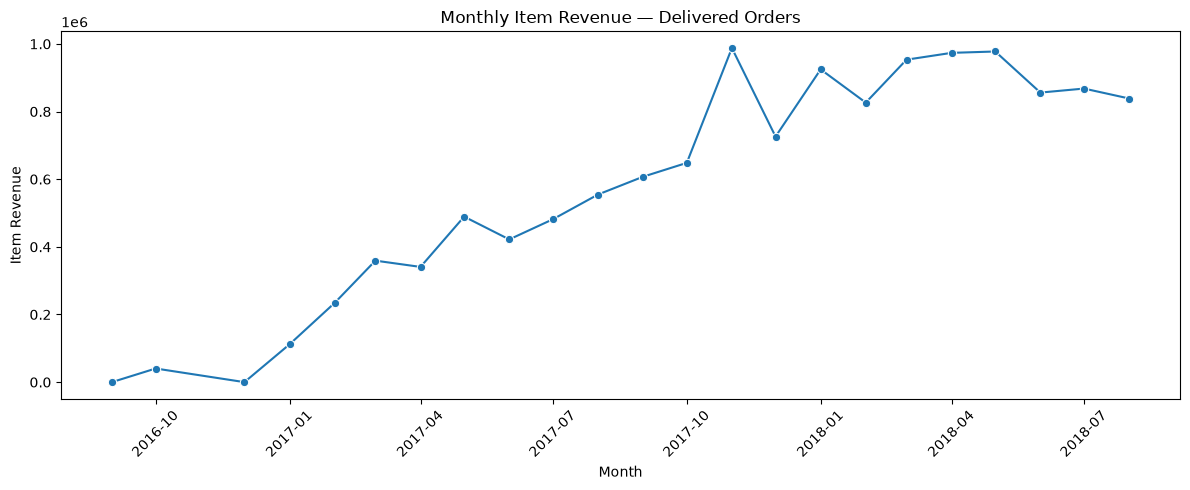

In [32]:
monthly_revenue["sales_month"] = pd.to_datetime(
    monthly_revenue["sales_month"]
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_revenue,
    x="sales_month",
    y="revenue",
    marker="o"
)

plt.title("Monthly Item Revenue — Delivered Orders")
plt.xlabel("Month")
plt.ylabel("Item Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Analyze customer behavior

### Calculate repeat-customer metrics

In [20]:
customer_orders = pd.read_sql_query("""
    SELECT
        c.customer_unique_id,
        COUNT(DISTINCT o.order_id) AS total_orders
    FROM olist_customers c
    JOIN olist_orders o
        ON c.customer_id = o.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id;
""", engine)

display(customer_orders.head())

,customer_unique_id,total_orders
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1


In [21]:
print("Unique customers:", len(customer_orders))
print(
    "Repeat customers:",
    (customer_orders["total_orders"] > 1).sum()
)
print(
    "One-time customers:",
    (customer_orders["total_orders"] == 1).sum()
)

print(
    "Repeat-customer rate:",
    round(
        (customer_orders["total_orders"] > 1).mean() * 100, 2
    ),
    "%"
)

Unique customers: 93358
Repeat customers: 2801
One-time customers: 90557
Repeat-customer rate: 3.0 %


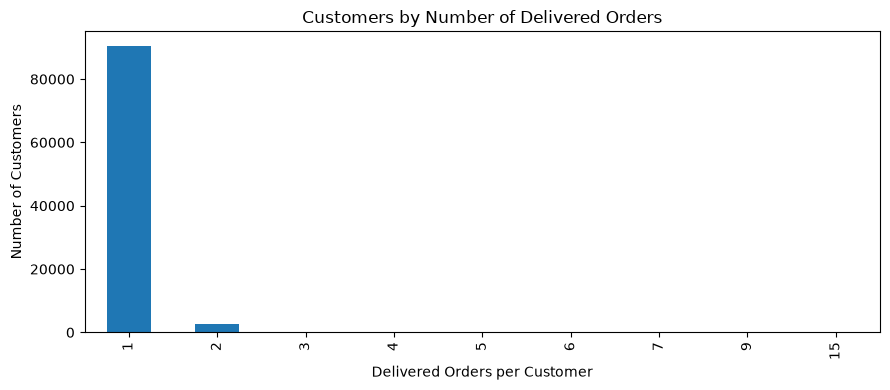

In [22]:
frequency_counts = (
    customer_orders["total_orders"]
    .value_counts()
    .sort_index()
)

frequency_counts.plot(kind="bar", figsize=(9, 4))
plt.title("Customers by Number of Delivered Orders")
plt.xlabel("Delivered Orders per Customer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Analyze products and geography

### Top 10 product categories by revenue

In [23]:
category_revenue = pd.read_sql_query("""
    SELECT
        COALESCE(
            t.product_category_name_english,
            p.product_category_name,
            'Unknown'
        ) AS product_category,
        COUNT(DISTINCT oi.order_id) AS orders,
        COUNT(*) AS item_rows,
        ROUND(SUM(oi.price::NUMERIC), 2) AS revenue
    FROM olist_order_items oi
    JOIN olist_orders o
        ON oi.order_id = o.order_id
    JOIN olist_products p
        ON oi.product_id = p.product_id
    LEFT JOIN product_category_translation t
        ON p.product_category_name = t.product_category_name
    WHERE o.order_status = 'delivered'
    GROUP BY 1
    ORDER BY revenue DESC
    LIMIT 10;
""", engine)

display(category_revenue)

,product_category,orders,item_rows,revenue
0,health_beauty,8647,9465,1233131.72
1,watches_gifts,5495,5859,1166176.98
2,bed_bath_table,9272,10953,1023434.76
3,sports_leisure,7530,8431,954852.55
4,computers_accessories,6530,7644,888724.61
5,furniture_decor,6307,8160,711927.69
6,housewares,5743,6795,615628.69
7,cool_stuff,3559,3718,610204.10
8,auto,3810,4140,578966.65
9,toys,3804,4030,471286.48


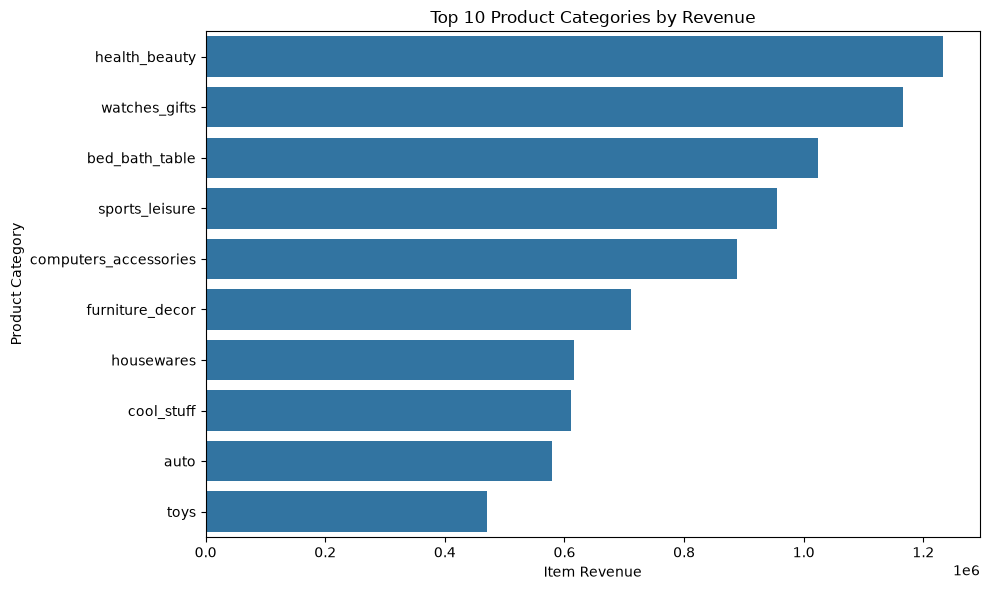

In [24]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=category_revenue,
    x="revenue",
    y="product_category"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Item Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

### Revenue by customer state

In [25]:
state_revenue = pd.read_sql_query("""
    SELECT
        c.customer_state,
        COUNT(DISTINCT o.order_id) AS orders,
        ROUND(SUM(oi.price::NUMERIC), 2) AS revenue
    FROM olist_orders o
    JOIN olist_customers c
        ON o.customer_id = c.customer_id
    JOIN olist_order_items oi
        ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_state
    ORDER BY revenue DESC;
""", engine)

display(state_revenue.head(10))

,customer_state,orders,revenue
0,SP,40501,5067633.16
1,RJ,12350,1759651.13
2,MG,11354,1552481.83
3,RS,5345,728897.47
4,PR,4923,666063.51
5,SC,3546,507012.13
6,BA,3256,493584.14
7,DF,2080,296498.41
8,GO,1957,282836.70
9,ES,1995,268643.45


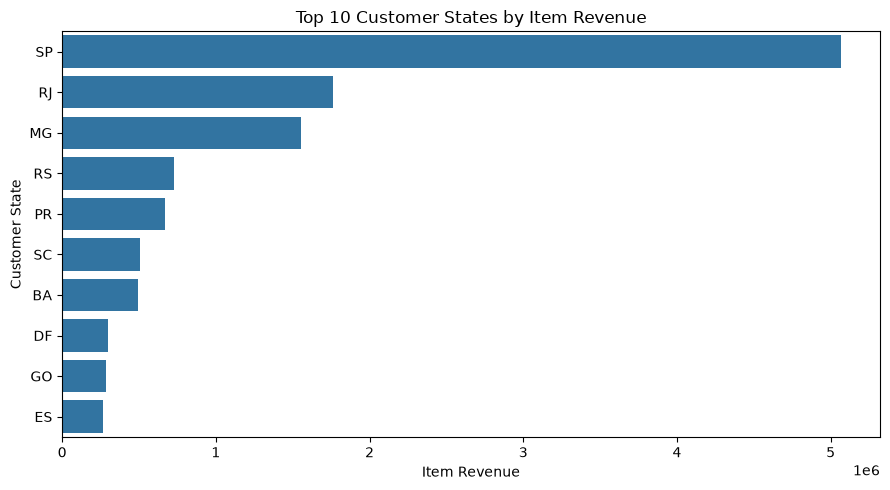

In [26]:
top_states = state_revenue.head(10)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=top_states,
    x="revenue",
    y="customer_state"
)

plt.title("Top 10 Customer States by Item Revenue")
plt.xlabel("Item Revenue")
plt.ylabel("Customer State")
plt.tight_layout()
plt.show()

# Perform RFM customer segmentation

In [27]:
rfm = pd.read_sql_query("""
    SELECT
        c.customer_unique_id,
        MAX(
            NULLIF(
                BTRIM(o.order_purchase_timestamp::TEXT), ''
            )::TIMESTAMP
        ) AS last_purchase_date,
        COUNT(DISTINCT o.order_id) AS frequency,
        SUM(oi.price::NUMERIC) AS monetary
    FROM olist_orders o
    JOIN olist_customers c
        ON o.customer_id = c.customer_id
    JOIN olist_order_items oi
        ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
      AND NULLIF(
          BTRIM(o.order_purchase_timestamp::TEXT), ''
      ) IS NOT NULL
    GROUP BY c.customer_unique_id;
""", engine)

display(rfm.head())

,customer_unique_id,last_purchase_date,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:00,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:00,1,18.90
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:00,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:00,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:00,1,180.00


In [28]:
rfm["last_purchase_date"] = pd.to_datetime(
    rfm["last_purchase_date"]
)

analysis_date = rfm["last_purchase_date"].max().normalize() + pd.Timedelta(days=1)

rfm["recency_days"] = (
    analysis_date - rfm["last_purchase_date"]
).dt.days

display(rfm[[
    "customer_unique_id",
    "recency_days",
    "frequency",
    "monetary"
]].head())

,customer_unique_id,recency_days,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,18.90
2,0000f46a3911fa3c0805444483337064,537,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00


In [29]:
rfm["R_score"] = pd.qcut(
    rfm["recency_days"].rank(method="first", ascending=False),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

display(rfm.head())

,customer_unique_id,last_purchase_date,frequency,monetary,recency_days,R_score,F_score,M_score,RFM_score
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:00,1,129.90,111,4,1,4,414
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:00,1,18.90,114,4,1,1,411
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:00,1,69.00,537,1,1,2,112
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:00,1,25.99,321,2,1,1,211
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:00,1,180.00,288,2,1,5,215


In [33]:
from pathlib import Path

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sales_summary.to_csv(
    OUTPUT_DIR / "sales_summary.csv", index=False
)

monthly_revenue.to_csv(
    OUTPUT_DIR / "monthly_revenue.csv", index=False
)

customer_orders.to_csv(
    OUTPUT_DIR / "customer_order_frequency.csv", index=False
)

category_revenue.to_csv(
    OUTPUT_DIR / "category_revenue_top10.csv", index=False
)

state_revenue.to_csv(
    OUTPUT_DIR / "state_revenue.csv", index=False
)

rfm.to_csv(
    OUTPUT_DIR / "customer_rfm.csv", index=False
)

print("All six analysis tables saved successfully!")

All six analysis tables saved successfully!
